# 01b - Preguntas e hipótesis (EDA)

## Objetivo de este cuaderno

Aquí respondemos a las preguntas 1 a 7 del EDA y hacemos una primera validación de las hipótesis H1, H2 y H3. Es **solo exploración**: leemos el CSV original de data/raw y no modificamos df. Los cortes se aplican sobre copias.

- **Lee:** data/raw/coches_segunda_mano.csv
- **Guarda:** solo figuras en outputs/figures

### Importar librerías

Cargamos pandas, numpy, matplotlib y seaborn, que usaremos en todo el análisis.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Cargar el dataset

Leemos el CSV de anuncios y mostramos las primeras filas para comprobar que la carga es correcta.

In [2]:
df = pd.read_csv('../data/raw/coches_segunda_mano.csv')
df.head()

,url,company,make,model,version,price,price_financed,fuel,year,kms,...,doors,shift,color,photos,is_professional,dealer,province,country,publish_date,insert_date
0,e158ae0ca53119ca199c28c36b5c2fcd,9881bcdd5a0ad4733037b3fb25e69c3a,SEAT,Toledo,SEAT Toledo 4p.,950,NaN,Diésel,2000.0,227000,...,4,Manual,Verde,5,False,0f4bb8455d27349b8273109b66a847f3,Navarra,Spain,2020-12-18 10:47:13,2021-01-15 00:00:00
1,ff267ebb7e700246f47f84f3db660b4b,9881bcdd5a0ad4733037b3fb25e69c3a,CITROEN,C1,CITROEN C1 PureTech 60KW 82CV Feel 5p.,6200,NaN,Gasolina,2017.0,50071,...,5,Manual,Blanco,6,True,Autos Raymara,Tenerife,Spain,2021-01-02 11:25:40,2021-01-15 00:00:00
2,de4b02db28ea7786c622b969be10c7c7,9881bcdd5a0ad4733037b3fb25e69c3a,FORD,Transit Connect,FORD Transit Connect Van 1.5 TDCi 100cv Ambien...,7851,7024.0,Diésel,2016.0,103000,...,4,Manual,Blanco,10,True,Auto 96,Barcelona,Spain,2020-12-16 10:51:45,2021-01-15 00:00:00
3,0449972a4d07594acf92e9a7dd28b39c,9881bcdd5a0ad4733037b3fb25e69c3a,VOLKSWAGEN,Caravelle,VOLKSWAGEN Caravelle Largo 2.0 TDI 140 Comfort...,19426,NaN,Diésel,2014.0,120000,...,4,Manual,Blanco,9,True,Inniauto,Navarra,Spain,2020-11-25 11:09:14,2021-01-15 00:00:00
4,12c4fa49bd4fdf23f19ecf396d3f02ef,9881bcdd5a0ad4733037b3fb25e69c3a,FORD,Transit,FORD Transit 350 96kW L4 Ambiente Propulsion T...,22850,22800.0,Diésel,2017.0,107000,...,2,Manual,Blanco,4,True,"Autofleet España,s.l",Sevilla,Spain,2021-01-12 20:00:34,2021-01-15 00:00:00


## Preguntas e hipótesis

### Hipótesis previas

Estas hipótesis se escribieron **antes de explorar los datos**. Se hace así para no ajustarlas a lo que vemos: si las escribiéramos después, sería muy fácil "acertar" siempre.

- **H1:** los coches de alta gama se deprecian (pierden valor con los años) más rápido.
- **H2:** Volkswagen se deprecia menos que la media.
- **H3:** comparando coches de año similar, los eléctricos son más caros que los diésel, y los diésel más que los gasolina.

En este EDA haremos una **primera validación con gráficos**. En 06_explicabilidad_negocio.ipynb las confirmaremos o refutaremos con SHAP, que muestra cuánto pesa cada variable en el precio que predice el modelo.

### Pregunta 1: ¿Cómo se distribuye el precio y qué valores raros hay?

**Por qué importa para el negocio:** el precio es lo que queremos predecir. Si casi todos los coches están en un rango y unos pocos son muy baratos o muy caros, debemos saberlo. Esos extremos pueden ser errores, chatarra o superdeportivos que la empresa no compraría, y pueden desviar el modelo. Además, conocer el rango habitual nos dice para qué coches será fiable la tasación.

**Lo que ya tenemos más arriba** (no lo repetimos):
- *Resumen de las variables numéricas* (df.describe()): mínimo 300 €, mediana 11.750 €, media 15.166 €, máximo 549.900 €.
- *Distribución de las variables numéricas* (histograma de price): cola larga a la derecha, asimetría ≈ 6,6.
- *Diagrama de caja*: el bigote acaba hacia 41.250 € y hay unos 2.205 anuncios por encima.
- *Recorte para el preprocesado* y *Decisión: cortes*: 7 anuncios por encima de 350.000 €.

Nos falta mirar **el extremo barato**, **los percentiles** y **el precio en escala logarítmica**.

### El precio en escala logarítmica

El precio tiene una cola muy larga a la derecha (asimetría ≈ 6,6): muchos coches baratos y pocos muy caros. El logaritmo "comprime" los valores grandes, de modo que una subida de 5.000 a 10.000 € ocupa lo mismo que de 50.000 a 100.000 €. Así vemos mejor la forma real de la distribución y comprobamos si al modelo le vendría bien predecir el log del precio.

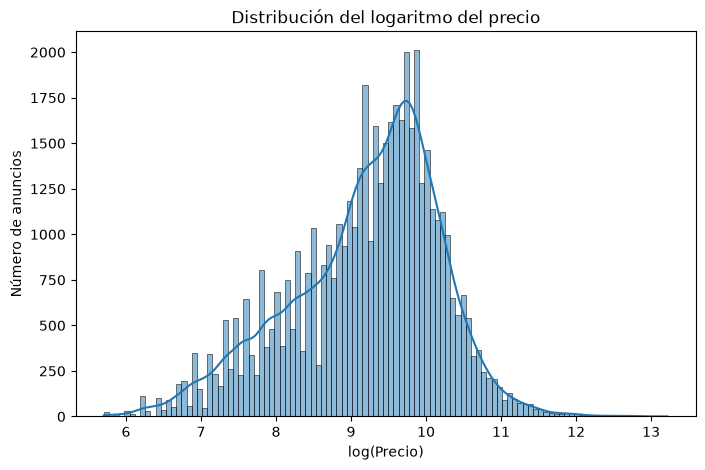

In [3]:
plt.figure(figsize=(8, 5))
sns.histplot(np.log(df['price']), kde=True)
plt.title('Distribución del logaritmo del precio')
plt.xlabel('log(Precio)')
plt.ylabel('Número de anuncios')
plt.savefig('../outputs/figures/03_distribucion_log_precio.png', bbox_inches='tight')
plt.show()

Contamos los coches con precio muy bajo y muy alto, y miramos los percentiles 1 y 99. Arriba solo habíamos mirado el extremo caro.

In [4]:
print('Coches con precio menor de 1.000 €:', (df['price'] < 1000).sum())
print('Coches con precio mayor de 100.000 €:', (df['price'] > 100000).sum())
print('Percentil 1:', df['price'].quantile(0.01))
print('Percentil 99:', df['price'].quantile(0.99))

Coches con precio menor de 1.000 €: 1012
Coches con precio mayor de 100.000 €: 195
Percentil 1: 750.0
Percentil 99: 72900.90000000018


### Observaciones (Pregunta 1)

- Juntando lo de arriba: el precio va de **300 €** a **549.900 €**, con mediana **11.750 €** y media **15.166 €**. La media sube por los coches muy caros.
- **Extremo barato:** hay **1.012** coches por debajo de 1.000 € (el 2 %). No lo habíamos mirado: el diagrama de caja no los marca, porque la cola está a la derecha.
- **Extremo caro:** **195** coches por encima de 100.000 € (el 0,4 %), de los que solo 7 pasan de 350.000 €.
- **Percentiles:** el 1 % es **750 €** y el 99 % es **72.901 €**. El 98 % de los anuncios cae en ese rango.
- **Escala logarítmica:** la asimetría baja de ≈ 6,6 a ≈ **−0,5** y la distribución se parece mucho más a una campana.



### Pregunta 2: ¿Cuánto se deprecia un coche por cada año de antigüedad?

**Por qué importa para el negocio:** la antigüedad es, junto con los kilómetros, lo primero que mira un tasador. Saber cuánto valor pierde de media un coche cada año nos da una regla sencilla para comprobar que el modelo tiene sentido, y es la base para estudiar las hipótesis H1 (alta gama) y H2 (Volkswagen).

Para esta pregunta usamos una copia, df_p2, con los cortes de precio que hemos decidido arriba (entre 1.000 € y 100.000 €). Así los coches de desguace y los superdeportivos no distorsionan la mediana. El df original no se modifica.

In [5]:
df_p2 = df[(df['price'] >= 1000) & (df['price'] <= 100000)]
df_p2.shape

(48793, 21)

Calculamos la mediana del precio por año de fabricación, desde 2000 hasta 2020. Usamos la mediana y no la media porque el precio tiene cola a la derecha. Dejamos fuera 2021 porque el dataset se capturó el 15-01-2021 y hay muy pocos anuncios de ese año.

In [6]:
df_p2_años = df_p2[(df_p2['year'] >= 2000) & (df_p2['year'] <= 2020)]
mediana_año = df_p2_años.groupby('year')['price'].median()
mediana_año

year
2000.0     2162.5
2001.0     2000.0
2002.0     2300.0
2003.0     2550.0
2004.0     2900.0
2005.0     3490.0
2006.0     3999.0
2007.0     4700.0
2008.0     5900.0
2009.0     6500.0
2010.0     7490.0
2011.0     8900.0
2012.0     9800.0
2013.0    11000.0
2014.0    12300.0
2015.0    14400.0
2016.0    15490.0
2017.0    16900.0
2018.0    16950.0
2019.0    20500.0
2020.0    24990.0
Name: price, dtype: float64

Cuántos anuncios hay en cada año, para saber si cada mediana se apoya en suficientes coches.

In [7]:
df_p2_años['year'].value_counts().sort_index()

year
2000.0     554
2001.0     653
2002.0     888
2003.0    1061
2004.0    1496
2005.0    1791
2006.0    1828
2007.0    2179
2008.0    1841
2009.0    1440
2010.0    1622
2011.0    1531
2012.0    1393
2013.0    1491
2014.0    1979
2015.0    3061
2016.0    5202
2017.0    4447
2018.0    3896
2019.0    4411
2020.0    4167
Name: count, dtype: int64

Gráfico de líneas de la mediana del precio por año.

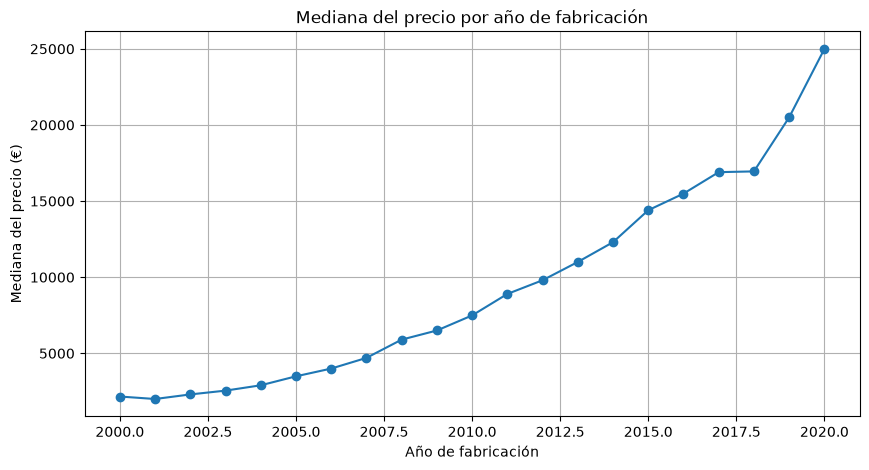

In [8]:
plt.figure(figsize=(10, 5))
plt.plot(mediana_año.index, mediana_año.values, marker='o')
plt.title('Mediana del precio por año de fabricación')
plt.xlabel('Año de fabricación')
plt.ylabel('Mediana del precio (€)')
plt.grid(True)
plt.savefig('../outputs/figures/04_mediana_precio_por_anio.png', bbox_inches='tight')
plt.show()

Calculamos cuánto se pierde al pasar de un año al anterior: si un coche de 2019 vale de mediana 20.500 € y uno de 2018 vale 16.950 €, un año más de antigüedad supone perder un 17 %. Lo hacemos para todos los años y sacamos la media y la mediana de esas pérdidas.

In [9]:
perdida_anual = (1 - mediana_año / mediana_año.shift(-1)) * 100
perdida_anual.round(1)

year
2000.0    -8.1
2001.0    13.0
2002.0     9.8
2003.0    12.1
2004.0    16.9
2005.0    12.7
2006.0    14.9
2007.0    20.3
2008.0     9.2
2009.0    13.2
2010.0    15.8
2011.0     9.2
2012.0    10.9
2013.0    10.6
2014.0    14.6
2015.0     7.0
2016.0     8.3
2017.0     0.3
2018.0    17.3
2019.0    18.0
2020.0     NaN
Name: price, dtype: float64

In [10]:
print('Pérdida media por año de antigüedad (%):', round(perdida_anual.mean(), 1))
print('Pérdida mediana por año de antigüedad (%):', round(perdida_anual.median(), 1))

Pérdida media por año de antigüedad (%): 11.3
Pérdida mediana por año de antigüedad (%): 12.4


### Observaciones (Pregunta 2)

- Para esta pregunta quedan **48.793** anuncios con precio entre 1.000 € y 100.000 €. Todos los años de 2000 a 2020 tienen al menos 554 anuncios, así que cada mediana se apoya en bastantes coches.
- La mediana baja de forma muy regular con la antigüedad: **24.990 €** para un coche de 2020, **14.400 €** para uno de 2015, **7.490 €** para uno de 2010 y **2.162 €** para uno de 2000.
- De media, **cada año de antigüedad resta alrededor de un 11-12 % del precio** (media 11,3 %, mediana 12,4 %). Como es un porcentaje, el coche pierde más euros cuando es nuevo que cuando ya es viejo: la curva es exponencial, no una recta.
- Los primeros años son los que más pesan: de 2020 a 2019 se pierde un 18 % y de 2019 a 2018 un 17,3 %.
- Hay saltos raros: de 2018 a 2017 casi no baja (0,3 %), y de 2001 a 2000 el precio incluso sube (+8,1 %). Pueden deberse a cambios en qué coches se anuncian cada año (más marcas premium o más kilómetros en unos años que en otros). Por eso la cifra es orientativa y la estudiaremos por marca.
- El salto de 2001 a 2000 se explica probablemente por **sesgo de supervivencia**: con más de 20 años solo siguen a la venta los coches bien conservados o apreciados (los demás ya se han desguazado), y además hay menos anuncios. Por eso, a partir de unos 15-20 años de antigüedad la depreciación deja de ser fiable.
- **Relación con las hipótesis:** esta cifra del 11-12 % anual es la referencia de "la media". Para **H1** compararemos la depreciación de las marcas de alta gama con este valor; para **H2**, la de Volkswagen. Todavía no concluimos nada: lo veremos por marca y lo confirmaremos con SHAP en 06_explicabilidad_negocio.
- **Idea para el modelado:** como la caída es exponencial, el logaritmo del precio baja casi en línea recta con el año. Es otro motivo para probar a predecir log(price), como se propuso en la Pregunta 1.
- **Propuesta para 03_preprocesado:** cortar por antigüedad y quedarnos con coches de **hasta 15 años** (fabricados en 2006 o después, ya que los datos se capturaron en 2021). Es una decisión de negocio: la empresa se centra en coches de 0 a 15 años, donde la caída del precio es clara y predecible. Dentro del rango de 1.000 € a 100.000 €, se perderían **7.979 anuncios** de 2005 o antes, el **16,4 %** de los 48.793.

### Pregunta 3: ¿Cuánto baja el precio por cada 10.000 km?

**Por qué importa para el negocio:** los kilómetros son, junto con el año, lo primero que mira un tasador. Saber cuánto valor resta cada 10.000 km nos da una regla sencilla para negociar con el cliente y para comprobar que el modelo tiene sentido.

Usamos una copia, df_p3, con los cortes ya decididos: precio entre 1.000 € y 100.000 €, hasta 1.000.000 km y coches de 2006 en adelante. El df original no se modifica.

In [11]:
df_p3 = df[(df['price'] >= 1000) & (df['price'] <= 100000) & (df['kms'] <= 1000000) & (df['year'] >= 2006)].copy()
df_p3.shape

(40802, 21)

Agrupamos los kilómetros en tramos de 10.000 km. Con la división entera (//) un coche de 47.300 km cae en el tramo 40.000. Nos quedamos hasta 300.000 km, porque por encima hay muy pocos anuncios por tramo.

In [12]:
df_p3['tramo_kms'] = (df_p3['kms'] // 10000) * 10000
df_p3_tramos = df_p3[df_p3['tramo_kms'] < 300000]
mediana_kms = df_p3_tramos.groupby('tramo_kms')['price'].median()
mediana_kms

tramo_kms
0         23990.0
10000     20200.0
20000     18900.0
30000     16990.0
40000     16200.0
50000     16000.0
60000     15599.0
70000     14900.0
80000     13990.0
90000     13900.0
100000    12725.0
110000    12000.0
120000    10900.0
130000    10890.0
140000     9500.0
150000     8999.0
160000     8400.0
170000     7990.0
180000     7500.0
190000     6600.0
200000     6000.0
210000     6200.0
220000     6000.0
230000     5825.0
240000     5400.0
250000     5300.0
260000     5500.0
270000     4800.0
280000     4600.0
290000     4969.5
Name: price, dtype: float64

Cuántos anuncios hay en cada tramo, para saber si cada mediana se apoya en suficientes coches.

In [13]:
df_p3_tramos['tramo_kms'].value_counts().sort_index()

tramo_kms
0         5578
10000     2617
20000     2340
30000     1810
40000     1851
50000     1830
60000     1873
70000     1874
80000     2023
90000     2196
100000    1530
110000    1657
120000    1619
130000    1463
140000    1345
150000    1215
160000    1084
170000     949
180000     870
190000     825
200000     683
210000     512
220000     532
230000     436
240000     366
250000     330
260000     261
270000     216
280000     169
290000     142
Name: count, dtype: int64

Gráfico de líneas de la mediana del precio por tramo de kilómetros.

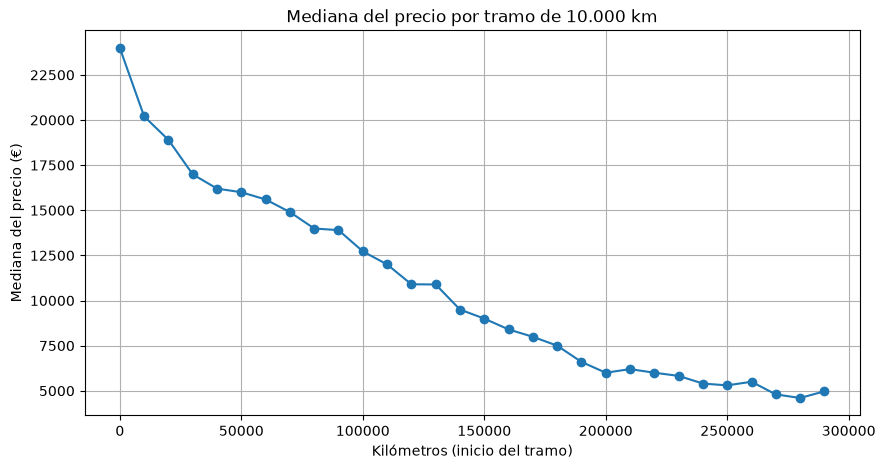

In [14]:
plt.figure(figsize=(10, 5))
plt.plot(mediana_kms.index, mediana_kms.values, marker='o')
plt.title('Mediana del precio por tramo de 10.000 km')
plt.xlabel('Kilómetros (inicio del tramo)')
plt.ylabel('Mediana del precio (€)')
plt.grid(True)
plt.savefig('../outputs/figures/05_mediana_precio_por_kms.png', bbox_inches='tight')
plt.show()

Calculamos cuánto baja la mediana, de media, por cada 10.000 km: la diferencia entre el primer y el último tramo, dividida entre el número de saltos de 10.000 km que hay entre ellos.

In [15]:
primer_tramo = mediana_kms.iloc[0]
ultimo_tramo = mediana_kms.iloc[-1]
saltos = len(mediana_kms) - 1
print('Mediana primer tramo (€):', primer_tramo)
print('Mediana último tramo (€):', ultimo_tramo)
print('Bajada media por cada 10.000 km (€):', round((primer_tramo - ultimo_tramo) / saltos))
print('Bajada media por cada 10.000 km (% del primer tramo):', round((primer_tramo - ultimo_tramo) / saltos / primer_tramo * 100, 1))

Mediana primer tramo (€): 23990.0
Mediana último tramo (€): 4969.5
Bajada media por cada 10.000 km (€): 656
Bajada media por cada 10.000 km (% del primer tramo): 2.7


Comprobamos la relación entre kilómetros y año: si los coches viejos tienen más kilómetros, parte de la bajada se debe a la edad.

In [16]:
print('Correlación entre kms y year:', round(df_p3['kms'].corr(df_p3['year']), 2))

Correlación entre kms y year: -0.77


### Observaciones (Pregunta 3)

- Para esta pregunta quedan **40.802** anuncios con los cortes (precio de 1.000 € a 100.000 €, hasta 1.000.000 km y de 2006 en adelante). Todos los tramos hasta 300.000 km tienen al menos 142 anuncios.
- La mediana baja de forma muy regular con los kilómetros: **23.990 €** con menos de 10.000 km, **12.725 €** entre 100.000 y 110.000 km, **6.000 €** entre 200.000 y 210.000 km y **4.970 €** entre 290.000 y 300.000 km.
- De media, **cada 10.000 km restan unos 656 €** de la mediana, alrededor de un **2,7 %** del precio del primer tramo.
- La bajada es más fuerte al principio: solo de 0 a 10.000 km se pierden casi 3.800 €. Muchos de esos coches son prácticamente nuevos (km 0 o seminuevos).
- **Ojo: kilómetros y año están muy relacionados** (correlación de −0,77). Los coches viejos tienen más kilómetros, así que **parte de esta bajada se debe a la edad** y no solo a los kilómetros. El modelo podrá separar el efecto de cada variable; en 06_explicabilidad_negocio lo veremos con SHAP.